# Demanda eléctrica por área del SEIN: modelado y evaluación

**TB1 · Metodología para Data Science (1ACC0240) · UPC · ciclo 2026-2 · Grupo 3**

Notebook 02 de CRISP-DM para el caso peruano: **modelado y evaluación en la validación de 2025**. Parte de los
datasets del [notebook 01](01_sein_datos_preparacion.ipynb) (`dataset_area`, con la regla de información) y de la
[spec del proyecto](https://github.com/R0SEWT/tetouan-power-forecast/blob/develop/docs/superpowers/specs/2026-10-23-demanda-sein-areas-design.md),
§7 y §8. La línea base ([`experimentos/sein`](../experimentos/sein/)) ya mostró que un Gradient Boosting en razón
le gana a la mejor referencia ingenua en las tres áreas y los dos horizontes en 2025: aquí se elige el modelo, se
mide qué aportan las exógenas y se compara reentrenar con no reentrenar.

**Lo que se elige aquí se elige en 2025. La prueba de 2026, El Niño extraordinario, no se toca en este notebook:**
las filas de 2026 se apartan en la primera celda y el modelo final se guarda para evaluarlo una sola vez, en el
notebook 03.

| Paso | Qué hace |
|---|---|
| 1. Datos y partición | Los datasets por área y el global, a 1 h y a 24 h, sin la prueba |
| 2. Referencias ingenuas | La vara: la mejor de persistencia, ayer y semana pasada en cada área |
| 3. Algoritmos y búsqueda de hiperparámetros | Ridge, Random Forest y Gradient Boosting con validación cruzada temporal, con M0 a 1 h |
| 4. Global o por área | Un modelo de las tres áreas frente a uno por área, con M0 a 1 h |
| 5. El horizonte de 24 h | Los mismos hiperparámetros, el programa del día siguiente |
| 6. Ablación de exógenas | M0 a M3 acumulando grupos y M3 quitando uno a la vez, con su intervalo |
| 7. Experimento de adaptación | Modelo fijo o reentrenado cada semana, con y sin exógenas; reentrenar cuando cambia la alerta de ENFEN |
| 8. Origen móvil mensual | Mes a mes de 2023 a 2025, M0 frente a M3 |
| 9. Errores por régimen | Horas de mayor demanda, feriados y fines de semana, fallas en curso, El Niño |
| 10. Diagnóstico | Real contra predicho y residuos |
| 11. Importancia de variables | Por permutación, por área y por grupo |
| 12. Hipótesis para 2026 y modelo final | Lo que se espera de la prueba, escrito antes de mirarla; el modelo que usa la app |

Corre en Colab con GPU: Gradient Boosting (XGBoost) entrena en la GPU, y Random Forest y Ridge en la CPU. Lo lento
es el reentrenamiento semanal (§7): alrededor de una hora y media en total si el modelo elegido es XGBoost, y unas
tres horas si es Random Forest. Con la variable de entorno `TPF_RAPIDO=1` corre en minutos sobre una muestra, solo para probar el notebook
de punta a punta.

**Hipótesis, escritas antes de ver 2025** (spec §1 y README):

- H1. A 1 h las exógenas aportan poco: la demanda reciente ya absorbe el nivel. M3 − M0 queda cerca de cero.
- H2. A 24 h las exógenas pueden aportar más, sobre todo en el Centro (Lima) y en la costa norte.
- H3. En un año normal como 2025, reentrenar cada semana cambia poco frente al modelo fijo; la diferencia debería
  aparecer en 2026, cuando el nivel se sale de lo visto.
- H4. El modelo global le gana o empata al modelo por área: las tres áreas en razón "hablan el mismo idioma" y
  el global ve tres veces más ejemplos.

# Configuración

En Colab se instala el código del repo y se monta Google Drive, donde viven las capas del medallón (las arman
`00_medallon_coes` y `00c_exogenas`). En local se usan las capas de `data/`.

In [1]:
import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and "TETOUAN_DATA" not in os.environ:
    RAMA = "develop"
    !pip install -q "git+https://github.com/R0SEWT/tetouan-power-forecast@{RAMA}"
    from tetouan_power_forecast.medallon import usar_drive
    usar_drive()
elif not EN_COLAB:
    os.environ.setdefault("TETOUAN_DATA", str(Path.cwd().parent / "data"))

In [2]:
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit

from tetouan_power_forecast.coes import cargar_demanda_areas
from tetouan_power_forecast.evaluacion import (
    bootstrap_diferencia_mae,
    errores,
    hora_objetivo,
    mae_por_grupo,
    plegados_mensuales,
)
from tetouan_power_forecast.exogenas import icen_disponible
from tetouan_power_forecast.medallon import raiz_datos
from tetouan_power_forecast.modelado_sein import (
    DISPOSITIVO,
    VARIANTES_ABLACION,
    bloques,
    candidatos,
    categoria_icen,
    columnas_sin_grupo,
    en,
    es_hora_pico,
    gradient_boosting_global,
    horas_mayor_demanda,
    mejor_referencia,
    predecir_global,
    predecir_local,
    portable,
    predecir_por_bloques,
    preparar_datasets,
    subestimacion_sobre_p90,
    tramo,
)
from tetouan_power_forecast.modelos import CVPorFecha
from tetouan_power_forecast.variables_sein import AREAS, GRUPOS, HORIZONTES, PASO, REFERENCIAS, columnas_variante

RAIZ = raiz_datos()
RAPIDO = os.environ.get("TPF_RAPIDO") == "1"  # corrida corta, solo para probar el notebook
SEMILLA = 0
N_FOLDS = 3 if RAPIDO else 5  # validación cruzada temporal de la búsqueda de hiperparámetros
ITERACIONES = ({"Random Forest": 2, "Gradient Boosting": 2, "Global": 2} if RAPIDO
               else {"Random Forest": 15, "Gradient Boosting": 30, "Global": 20})  # combinaciones probadas
AREA_BUSQUEDA = "CENTRO"  # donde se buscan los hiperparámetros: dos tercios de la demanda del SEIN
FRECUENCIA_REENTRENO = "MS" if RAPIDO else "W-MON"  # cada lunes a las 00:00 (spec §8.4)
DESDE_MOVIL = "2025-10-01" if RAPIDO else "2023-01-01"  # primer mes del origen móvil (spec §8.5)
NOMBRES = {a: a.capitalize() for a in AREAS}
NOMBRES_REF = {"persistencia": "Persistencia", "ayer": "Ayer", "semana_pasada": "Semana pasada"}
COLORES = {"NORTE": "#E69F00", "CENTRO": "#0072B2", "SUR": "#009E73"}
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
import warnings
warnings.filterwarnings("ignore", message=".*mismatched devices.*")  # XGBoost predice desde pandas con el modelo en la GPU
print("XGBoost entrena en:", DISPOSITIVO)
if RAPIDO:
    print("Corrida rápida: pocas combinaciones, reentrenamiento mensual y origen móvil desde", DESDE_MOVIL)

XGBoost entrena en: cuda


# Modelado

## 1. Datos y partición

Cada área y horizonte tiene su dataset con las **variables en razón** (`dataset_area`, del notebook 01): la
demanda del área en t, t−1, t−2 y t−4, la de ayer y la de la semana pasada a la hora de t+H, la media y la
desviación de la última hora, todo dividido por la media de las últimas 24 h del área (`Area_*`); las otras dos
áreas igual, divididas por su propia media; el nivel reciente (`Area_m24_vs_m7d`); el calendario diario y semanal
de t y de t+H, feriados y cuarentena; y las exógenas por grupos (`clima`, `nino`, `fallas`), cada una con lo que
ya se había publicado en t. El modelo aprende `demanda(t+H) / media_24h(t)` y la predicción vuelve a MW.

El **dataset global** apila las tres áreas con solo sus propias variables y el área como categórica, sobre las
mismas filas que los datasets por área, así las predicciones de los dos se comparan periodo a periodo.

Partición (spec §8.1): entrenamiento 2016-2024, validación 2025 y prueba 2026, con un hueco de H pasos antes de
cada corte. **Las filas de la prueba se apartan aquí y no vuelven a aparecer.** Las filas son las completas para
M0 a M3 (`filas_comunes`): M4 espera el SAIDI por área.

In [3]:
demanda = cargar_demanda_areas()
silver_exo = RAIZ / "exogenas" / "silver"
exogenas = {
    "temperatura": pd.read_parquet(silver_exo / "temperatura_areas.parquet"),
    "icen": pd.read_parquet(silver_exo / "icen.parquet"),
    "nino12": pd.read_parquet(silver_exo / "nino12_semanal.parquet"),
    "eventos": pd.read_parquet(silver_exo / "eventos_coes.parquet"),
}
try:
    import holidays
    FERIADOS = list(holidays.PE(years=range(2016, 2027)))
except ImportError:
    FERIADOS = []
    print("sin el paquete holidays: los feriados quedan en cero")

if RAPIDO:  # una muestra: los últimos dos años y medio
    demanda = demanda[demanda["DateTime"] >= "2023-06-01"].reset_index(drop=True)

datos, filas = {}, []
for nombre_h, h in HORIZONTES.items():
    locales, global_ = preparar_datasets(demanda, h, variantes=VARIANTES_ABLACION, feriados=FERIADOS, **exogenas)
    # La prueba de 2026 se aparta: de aquí en adelante solo existen entrenamiento, validación y su hueco
    datos[nombre_h] = {"locales": {a: tramo(d, "desarrollo").reset_index(drop=True) for a, d in locales.items()},
                       "global": tramo(global_, "desarrollo").reset_index(drop=True)}
    for a in AREAS:
        d = datos[nombre_h]["locales"][a]
        conteo = d["particion"].value_counts()
        filas.append({"Horizonte": nombre_h, "Área": NOMBRES[a], "Entrenamiento": conteo.get("entrenamiento", 0),
                      "Validación": conteo.get("validacion", 0), "Desde": d["DateTime"].min(),
                      "Hasta": d["DateTime"].max(), "Variables M0": len(columnas_variante(d, "M0")) - 1,
                      "Variables M3": len(columnas_variante(d, "M3")) - 1})
display(pd.DataFrame(filas).set_index(["Horizonte", "Área"]))
for nombre_h in HORIZONTES:
    assert not (datos[nombre_h]["global"]["particion"] == "prueba").any()
    assert (datos[nombre_h]["global"]["DateTime"] < pd.Timestamp("2026-01-01")).all()
print("Variables de M3 del dataset global a 1 h:", columnas_variante(datos["1h"]["global"], "M3"))

Entrenamiento  Validación      Desde               Hasta  Variables M0  Variables M3
Horizonte Área                                                                                        
1h        Norte          154791       17518 2016-01-08 2025-12-31 22:30:00            26            33
          Centro         154791       17518 2016-01-08 2025-12-31 22:30:00            26            33
          Sur            154791       17518 2016-01-08 2025-12-31 22:30:00            26            33
24h       Norte          154423       17472 2016-01-08 2025-12-30 23:30:00            26            33
          Centro         154423       17472 2016-01-08 2025-12-30 23:30:00            26            33
          Sur            154423       17472 2016-01-08 2025-12-30 23:30:00            26            33

Variables de M3 del dataset global a 1 h: ['area_cod', 'Hour', 'MinuteOfDay', 'DayOfWeek', 'Time_Sin', 'Time_Cos', 'Week_Sin', 'Week_Cos', 'Obj_Sin', 'Obj_Cos', 'DiaSemanaObjetivo', 'FinDeSemanaObjetivo', 'FeriadoObjetivo', 'Cuarentena', 'Area_t', 'Area_t_menos_1', 'Area_t_menos_2', 'Area_t_menos_4', 'Area_ayer', 'Area_semana_pasada', 'Area_media_1h', 'Area_desv_1h', 'Area_m24_vs_m7d', 'media_24h', 'temp', 'temp_media_24h', 'temp_anomalia', 'temp_objetivo', 'icen', 'nino12_ssta', 'fallas_en_curso']


## 2. Referencias ingenuas

La vara que el modelo tiene que superar en cada área (spec §8.2): persistencia, ayer a la misma hora y semana
pasada a la misma hora. A 24 h, ayer coincide con la persistencia. Se calculan en la validación de 2025.

In [4]:
def tabla_referencias(nombre_h, nombre_tramo="validacion"):
    filas = []
    for a, d in datos[nombre_h]["locales"].items():
        t = tramo(d, nombre_tramo)
        for ref in REFERENCIAS:
            e = errores(t["real"], t[ref])
            filas.append({"Horizonte": nombre_h, "Área": NOMBRES[a], "Referencia": NOMBRES_REF[ref],
                          "MAE (MW)": e["MAE (kW)"], "RMSE (MW)": e["RMSE (kW)"], "MAPE (%)": e["MAPE (%)"]})
    return pd.DataFrame(filas).set_index(["Horizonte", "Área", "Referencia"])


referencias_val = pd.concat([tabla_referencias(h) for h in HORIZONTES])
display(referencias_val.round(2))
MEJOR_REF = {h: {a: mejor_referencia(tramo(d, "validacion")) for a, d in datos[h]["locales"].items()}
             for h in HORIZONTES}
for h in HORIZONTES:
    print(f"Mejor referencia a {h}:", {NOMBRES[a]: NOMBRES_REF[r] for a, r in MEJOR_REF[h].items()})


def mae_mejor_ref(nombre_h, a, nombre_tramo="validacion"):
    t = tramo(datos[nombre_h]["locales"][a], nombre_tramo)
    return errores(t["real"], t[MEJOR_REF[nombre_h][a]])["MAE (kW)"]

MAE (MW)  RMSE (MW)  MAPE (%)
Horizonte Área   Referencia                                  
1h        Norte  Persistencia      38.54      49.35      3.64
                 Ayer              55.54      78.17      5.37
                 Semana pasada     40.57      59.09      3.90
          Centro Persistencia     122.69     159.62      2.99
                 Ayer             213.51     327.66      5.21
                 Semana pasada    141.10     234.60      3.44
          Sur    Persistencia      32.14      54.34      1.94
                 Ayer              65.71     127.42      4.27
                 Semana pasada     94.47     154.32      5.95
24h       Norte  Persistencia      55.35      77.92      5.34
                 Ayer              55.35      77.92      5.34
                 Semana pasada     40.56      59.09      3.90
          Centro Persistencia     212.46     326.29      5.18
                 Ayer             212.46     326.29      5.18
                 Semana pasada    141.20     234.83      3.44
          Sur    Persistencia      65.66     127.48      4.27
                 Ayer              65.66     127.48      4.27
                 Semana pasada     94.65     154.52      5.96

Mejor referencia a 1h: {'Norte': 'Persistencia', 'Centro': 'Persistencia', 'Sur': 'Persistencia'}
Mejor referencia a 24h: {'Norte': 'Semana pasada', 'Centro': 'Semana pasada', 'Sur': 'Persistencia'}


## 3. Algoritmos y búsqueda de hiperparámetros

Tres familias (spec §7, criterio V de la rúbrica), todas con el objetivo en razón y con **M0 a 1 h** en el
**Centro**, que concentra dos tercios de la demanda:

- **Ridge** (scikit-learn, en la CPU): regresión lineal con regularización L2, con las variables estandarizadas. Si
  las variables en razón ya dicen casi todo, un modelo lineal debería andar bien.
- **Random Forest** (scikit-learn, en la CPU con todos los núcleos): árboles promediados; capta no linealidades e
  interacciones (hora × día de la semana). Con `max_samples` ≤ 0.3: cada árbol ve una muestra chica de los 155,000
  periodos.
- **Gradient Boosting** (XGBoost, en la GPU): árboles que corrigen a los anteriores; suele ser el más preciso en
  datos tabulares.

**Qué va a la GPU, y por qué.** Antes de esta corrida se midió cada implementación con el dataset real del Centro
a 1 h (M0), en una L4:

| Implementación | MAE en 2025 (MW) | Ajuste | Reproducible |
|---|---|---|---|
| Gradient Boosting, scikit-learn (`HistGradientBoostingRegressor`), CPU | 54.54 | 4.7 s | sí |
| **Gradient Boosting, XGBoost, GPU** | **54.15** | **2.2 s** | sí |
| **Random Forest, scikit-learn, CPU** | **54.70** | **17.6 s** | sí |
| Random Forest, cuML, GPU | 54.71 | 3.4 s | no: hasta 29 MW de diferencia entre dos ajustes |
| Random Forest, XGBoost (`num_parallel_tree`), GPU | 54.63 a 54.87 | 74 a 119 s | sí |

XGBoost en la GPU es más rápido y más preciso, y determinista. Para Random Forest no hay una opción en la GPU que
sea a la vez reproducible y más rápida: la de cuML cambia de un ajuste a otro con la misma semilla (y al pasarla a
scikit-learn su MAE sube a 55.56 MW), y la de XGBoost tarda más que la CPU. Se queda en scikit-learn. Con el tiempo
que ahorra XGBoost, la búsqueda prueba más combinaciones que en la versión en CPU.

Los hiperparámetros se buscan con **validación cruzada temporal** (`TimeSeriesSplit`, 5 folds, hueco de H
pasos) **solo sobre el entrenamiento**, minimizando el MAE en MW. Ridge en grilla; los otros dos, con búsqueda
aleatoria. La validación de 2025 queda para comparar los modelos ya ajustados. Los hiperparámetros que ganan se
reutilizan en las otras áreas y a 24 h (cómputo acotado, spec §7).

No hay desbalance que tratar: es una regresión. Su equivalente, que las horas de mayor demanda pesen poco en el
error medio, se revisa aparte en §9. Las métricas son las de la clase de regresión: MAE, RMSE, MAPE y R², siempre
en MW. Para elegir se usa el MAE, que es lo que el criterio de éxito compara con la mejor referencia; el R² se
reporta porque se lee fácil, pero con una serie tan autocorrelada hasta la persistencia lo tiene cerca de 1.

In [5]:
H1 = HORIZONTES["1h"]
tr_b = tramo(datos["1h"]["locales"][AREA_BUSQUEDA], "entrenamiento")
COLS_M0 = columnas_variante(tr_b, "M0")
cv = TimeSeriesSplit(n_splits=N_FOLDS, gap=H1)

busquedas, filas = {}, []
for nombre, (modelo, espacio) in candidatos(SEMILLA).items():
    if nombre in ITERACIONES:
        busqueda = RandomizedSearchCV(modelo, espacio, n_iter=ITERACIONES[nombre], cv=cv,
                                      scoring="neg_mean_absolute_error", random_state=SEMILLA)
    else:
        busqueda = GridSearchCV(modelo, espacio, cv=cv, scoring="neg_mean_absolute_error")
    inicio = time.time()
    busqueda.fit(tr_b[COLS_M0], tr_b["real"])
    busquedas[nombre] = busqueda
    i = busqueda.best_index_
    filas.append({
        "Algoritmo": nombre,
        "Combinaciones": len(busqueda.cv_results_["params"]),
        "MAE CV (MW)": -busqueda.best_score_,
        "Desv. entre folds (MW)": busqueda.cv_results_["std_test_score"][i],
        "Minutos": (time.time() - inicio) / 60,
        "Mejores hiperparámetros": {k.split("__")[-1]: (round(v, 4) if isinstance(v, float) else v)
                                    for k, v in busqueda.best_params_.items()},
    })
    print(f"{nombre}: listo en {(time.time() - inicio) / 60:.1f} min", flush=True)
tabla_busqueda = pd.DataFrame(filas).set_index("Algoritmo")
display(tabla_busqueda.round(2))

Ridge: listo en 0.1 min


Random Forest: listo en 9.1 min


Gradient Boosting: listo en 3.0 min


,Combinaciones,MAE CV (MW),Desv. entre folds (MW),Minutos,Mejores hiperparámetros
Algoritmo,,,,,
Ridge,13,72.80,4.42,0.08,{'alpha': 100.0}
Random Forest,15,51.79,4.07,9.14,"{'n_estimators': 100, 'min_samples_leaf': 5, '..."
Gradient Boosting,30,50.34,4.02,3.01,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."


Cada algoritmo, con sus mejores hiperparámetros y reentrenado con todo el entrenamiento, se evalúa en la validación
del área donde se buscó:

In [6]:
va_b = tramo(datos["1h"]["locales"][AREA_BUSQUEDA], "validacion")
predicciones_val_b = {nombre: b.best_estimator_.predict(va_b[COLS_M0]) for nombre, b in busquedas.items()}
ref_b = MEJOR_REF["1h"][AREA_BUSQUEDA]
predicciones_val_b[f"Mejor referencia ({NOMBRES_REF[ref_b]})"] = va_b[ref_b].to_numpy()
tabla_algoritmos = pd.DataFrame({k: errores(va_b["real"], p) for k, p in predicciones_val_b.items()}).T
tabla_algoritmos.columns = ["MAE (MW)", "RMSE (MW)", "MAPE (%)"]
tabla_algoritmos["R²"] = [r2_score(va_b["real"], p) for p in predicciones_val_b.values()]
tabla_algoritmos["Mejora vs. mejor referencia (%)"] = 100 * (1 - tabla_algoritmos["MAE (MW)"] / tabla_algoritmos["MAE (MW)"].iloc[-1])
display(tabla_algoritmos.round(2).style.set_caption(f"Validación de 2025, {NOMBRES[AREA_BUSQUEDA]}, M0 a 1 h"))

,MAE (MW),RMSE (MW),MAPE (%),R²,Mejora vs. mejor referencia (%)
Ridge,80.510000,111.040000,1.950000,0.940000,34.380000
Random Forest,54.620000,78.410000,1.330000,0.970000,55.480000
Gradient Boosting,53.120000,74.440000,1.290000,0.970000,56.710000
Mejor referencia (Persistencia),122.690000,159.620000,2.990000,0.880000,0.000000


## 4. Un modelo global o uno por área

En vez de un modelo por área, un solo Gradient Boosting (XGBoost) aprende de las tres áreas apiladas, con el
código del área (0, 1, 2) como variable y solo las variables de la propia área; con dos cortes, un árbol separa
cualquier área. Como el objetivo y las variables están en razón, las
tres áreas hablan el mismo idioma y el modelo ve tres veces más ejemplos de cada situación. En Tetuán, el global
sumó entre 5 y 10 % de mejora; aquí hay doce años por área, así que la ventaja puede ser menor (H4).

Sus hiperparámetros se buscan con la misma validación cruzada temporal, ahora sobre las fechas (`CVPorFecha`): las
tres áreas de una misma fecha quedan siempre del mismo lado.

In [7]:
global_1h = datos["1h"]["global"]
tr_g = tramo(global_1h, "entrenamiento")
COLS_G_M0 = columnas_variante(global_1h, "M0")
busqueda_global = RandomizedSearchCV(
    gradient_boosting_global(SEMILLA), candidatos(SEMILLA)["Gradient Boosting"][1],
    n_iter=ITERACIONES["Global"], cv=CVPorFecha(n_splits=N_FOLDS, gap=H1),
    scoring="neg_mean_absolute_error", random_state=SEMILLA,
)
inicio = time.time()
busqueda_global.fit(tr_g[COLS_G_M0], tr_g["real"], groups=tr_g["DateTime"])
print(f"Búsqueda del modelo global: {(time.time() - inicio) / 60:.1f} min")
print("MAE CV (MW, las tres áreas):", round(-busqueda_global.best_score_, 2))
print("Mejores hiperparámetros:", {k.split("__")[-1]: (round(v, 4) if isinstance(v, float) else v)
                                   for k, v in busqueda_global.best_params_.items()})

Búsqueda del modelo global: 2.8 min
MAE CV (MW, las tres áreas): 29.94
Mejores hiperparámetros: {'colsample_bytree': 0.7, 'learning_rate': np.float64(0.0358), 'max_depth': 10, 'min_child_weight': 20, 'n_estimators': 800, 'reg_lambda': 1.0, 'subsample': 0.85}


Se comparan en la validación de las tres áreas los tres algoritmos **por área** (con los hiperparámetros que
ganaron en el Centro), el **modelo global** y la **mejor referencia** de cada área. Para elegir se usa la mejora
del MAE frente a la mejor referencia, promediada entre las tres áreas: es lo que pide el criterio de éxito y no
favorece al Centro, que tiene más demanda.

In [8]:
MODELOS = {f"{nombre} por área": b.best_estimator_ for nombre, b in busquedas.items()}
MODELOS["Gradient Boosting global"] = busqueda_global.best_estimator_


def ajustar_y_predecir(nombre_h, columnas, entrenar, evaluar, metodo=None, conjunto=None):
    # Predicciones por área de un método, entrenado y evaluado en las filas indicadas; `columnas` es una variante,
    # una función del dataset o una lista; `conjunto` cambia los datasets (por defecto, `datos`)
    metodo = metodo or ELEGIDO
    conjunto = conjunto or datos
    if metodo.endswith("global"):
        return predecir_global(MODELOS[metodo], conjunto[nombre_h]["global"], columnas, entrenar, evaluar)
    return predecir_local(MODELOS[metodo], conjunto[nombre_h]["locales"], columnas, entrenar, evaluar)


def comparar(nombre_h, predicciones, nombre_tramo="validacion"):
    # MAE, MAPE y mejora frente a la mejor referencia de cada área, para {método: {área: predicciones}}
    filas = []
    for metodo, por_area in predicciones.items():
        for a in AREAS:
            t = tramo(datos[nombre_h]["locales"][a], nombre_tramo)
            e = errores(t["real"], por_area[a])
            filas.append({"Método": metodo, "Área": NOMBRES[a], "MAE (MW)": e["MAE (kW)"], "RMSE (MW)": e["RMSE (kW)"],
                          "MAPE (%)": e["MAPE (%)"], "R²": r2_score(t["real"], por_area[a]),
                          "Mejora vs. mejor referencia (%)": 100 * (1 - e["MAE (kW)"] / mae_mejor_ref(nombre_h, a, nombre_tramo))})
    return pd.DataFrame(filas)


candidatos_val = {m: ajustar_y_predecir("1h", "M0", en("entrenamiento"), en("validacion"), metodo=m) for m in MODELOS}
comparacion_val = comparar("1h", candidatos_val)
display(comparacion_val.pivot(index="Método", columns="Área").round(2))
mejora_media = comparacion_val.groupby("Método")["Mejora vs. mejor referencia (%)"].mean().sort_values(ascending=False)
print("Mejora media frente a la mejor referencia (%), M0 a 1 h:")
print(mejora_media.round(2).to_string())
ELEGIDO = mejora_media.index[0]
ALTERNATIVO = "Gradient Boosting por área" if ELEGIDO.endswith("global") else "Gradient Boosting global"
print("\nModelo elegido:", ELEGIDO, "· alternativa que se sigue reportando:", ALTERNATIVO)

MAE (MW)               RMSE (MW)               MAPE (%)                 R²             Mejora vs. mejor referencia (%)              
Área                         Centro  Norte    Sur    Centro  Norte    Sur   Centro Norte   Sur Centro Norte   Sur                          Centro  Norte    Sur
Método                                                                                                                                                         
Gradient Boosting global      53.54  19.59  24.72     75.17  25.26  50.81     1.30  1.88  1.61   0.97  0.95  0.83                           56.37  49.16  23.11
Gradient Boosting por área    53.12  19.58  24.79     74.44  25.34  51.57     1.29  1.88  1.61   0.97  0.95  0.82                           56.71  49.20  22.87
Random Forest por área        54.62  19.67  24.06     78.41  25.64  49.30     1.33  1.88  1.54   0.97  0.95  0.84                           55.48  48.97  25.14
Ridge por área                80.51  26.05  28.17    111.04  34.30  50.61     1.95  2.49  1.74   0.94  0.91  0.83                           34.38  32.40  12.36

Mejora media frente a la mejor referencia (%), M0 a 1 h:
Método
Random Forest por área        43.20
Gradient Boosting por área    42.93
Gradient Boosting global      42.88
Ridge por área                26.38

Modelo elegido: Random Forest por área · alternativa que se sigue reportando: Gradient Boosting global


## 5. El horizonte de 24 h

El programa del día siguiente, comparable con la Programación Diaria del COES. Reutiliza los hiperparámetros de
1 h (spec §7). A 24 h las referencias son más débiles (la persistencia es la demanda de hace un día) y el modelo
tiene margen para aportar más.

In [9]:
candidatos_24h = {m: ajustar_y_predecir("24h", "M0", en("entrenamiento"), en("validacion"), metodo=m)
                  for m in [ELEGIDO, ALTERNATIVO]}
comparacion_24h = comparar("24h", candidatos_24h)
display(comparacion_24h.pivot(index="Método", columns="Área").round(2).style.set_caption("Validación de 2025, M0 a 24 h"))

# Evaluación en 2025

Todo lo que sigue usa el modelo elegido en la validación de 2025. Lo que se reporta con intervalo sale de un
*bootstrap* de días: los errores de periodos cercanos están correlacionados y remuestrear periodos sueltos daría
intervalos demasiado estrechos.

## 6. Ablación de exógenas

Dos cadenas (spec §8.3), a 1 h y a 24 h:

- **Acumulativa:** M0 (demanda y calendario), M1 (+ clima), M2 (+ El Niño), M3 (+ fallas en curso).
- **Quitando un grupo desde M3:** sin clima, sin El Niño, sin fallas. Mide lo que aporta cada grupo por su cuenta;
  en la cadena acumulativa, el aporte de El Niño después del clima es casi cero por construcción.

Cada diferencia de MAE con M0 (o con M3, en la segunda cadena) va con su intervalo al 95 %. **Hipótesis H1 y H2:**
a 1 h, cerca de cero; a 24 h, algo más, sobre todo en el Centro y el Norte.

In [10]:
VARIANTES = {**{v: v for v in VARIANTES_ABLACION},
             **{f"M3 sin {g}": (lambda d, g=g: columnas_sin_grupo(d, g)) for g in ["clima", "nino", "fallas"]}}
predicciones_ablacion, filas = {}, []
for nombre_h in HORIZONTES:
    inicio = time.time()
    predicciones_ablacion[nombre_h] = {v: ajustar_y_predecir(nombre_h, cols, en("entrenamiento"), en("validacion"))
                                       for v, cols in VARIANTES.items()}
    for v, por_area in predicciones_ablacion[nombre_h].items():
        base = "M3" if v.startswith("M3 sin") else "M0"
        for a in AREAS:
            t = tramo(datos[nombre_h]["locales"][a], "validacion")
            e = errores(t["real"], por_area[a])
            fila = {"Horizonte": nombre_h, "Variante": v, "Área": NOMBRES[a], "MAE (MW)": e["MAE (kW)"],
                    "MAPE (%)": e["MAPE (%)"],
                    "Mejora vs. mejor referencia (%)": 100 * (1 - e["MAE (kW)"] / mae_mejor_ref(nombre_h, a))}
            if v != base:
                dif, bajo, alto = bootstrap_diferencia_mae(t["real"], por_area[a], predicciones_ablacion[nombre_h][base][a],
                                                           t["DateTime"], semilla=SEMILLA)
                fila.update({f"Δ MAE vs. {base} (MW)": dif, "IC 95 % bajo": bajo, "IC 95 % alto": alto})
            filas.append(fila)
    print(f"{nombre_h}: {(time.time() - inicio) / 60:.1f} min", flush=True)
ablacion = pd.DataFrame(filas)
display(ablacion.pivot(index=["Horizonte", "Variante"], columns="Área", values="MAE (MW)").round(2)
        .style.set_caption("MAE (MW) en la validación de 2025"))
display(ablacion.dropna(subset=["IC 95 % bajo"]).set_index(["Horizonte", "Variante", "Área"])[
    ["Δ MAE vs. M0 (MW)", "Δ MAE vs. M3 (MW)", "IC 95 % bajo", "IC 95 % alto"]].round(2)
        .style.set_caption("Diferencia de MAE con su intervalo: negativo, la variante mejora; si el intervalo cruza el cero, no se distingue"))

1h: 2.3 min


24h: 2.4 min


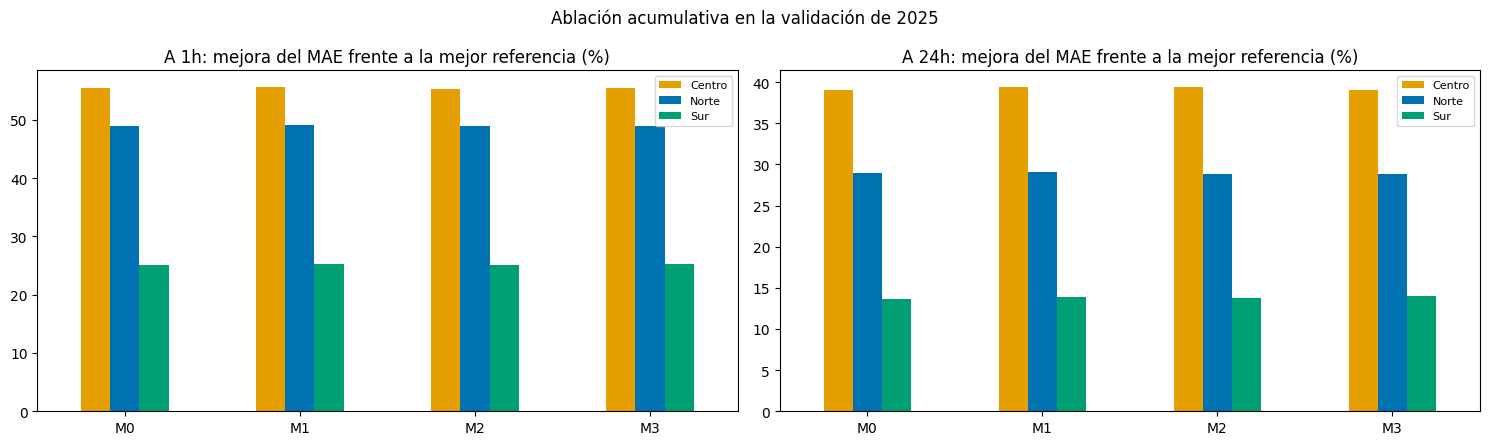

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)
for eje, nombre_h in zip(ejes, HORIZONTES):
    t = ablacion[(ablacion["Horizonte"] == nombre_h) & ablacion["Variante"].isin(VARIANTES_ABLACION)]
    t.pivot(index="Variante", columns="Área", values="Mejora vs. mejor referencia (%)").plot.bar(
        ax=eje, color=[COLORES[a] for a in AREAS], rot=0)
    eje.set_title(f"A {nombre_h}: mejora del MAE frente a la mejor referencia (%)")
    eje.set_xlabel("")
    eje.legend(fontsize=8)
plt.suptitle("Ablación acumulativa en la validación de 2025")
plt.tight_layout()
plt.show()

## 7. Experimento de adaptación

Cómo se sostiene el pronóstico cuando cambia el nivel (spec §8.4), medido primero en 2025 para después repetirlo en
2026 sin elegir nada:

| | Sin exógenas (M0) | Con exógenas (M3) |
|---|---|---|
| **Modelo fijo** (entrenado hasta 2024) | A | B |
| **Reentrenado cada semana** (ventana creciente, hueco de H pasos) | C | D |

Más la quinta variante: **reentrenar cuando cambia la categoría del ICEN** que ya se conocía en t (la alerta de
ENFEN, con su rezago de publicación), sola y como disparador extra sobre la semanal. Dispara pocas veces: se
presenta como costo frente a beneficio. Los hiperparámetros quedan congelados. **Hipótesis H3:** en 2025, C − A y
D − B cerca de cero.

In [12]:
POLITICAS = {"fijo": "fijo", "semanal": "periodica", "alerta ENFEN": "alerta", "semanal + alerta": "periodica+alerta"}
adaptacion, predicciones_adaptacion = [], {}
for nombre_h, h in HORIZONTES.items():
    inicio = time.time()
    hueco = h * PASO
    fechas_val = tramo(datos[nombre_h]["global"], "validacion")["DateTime"].drop_duplicates().sort_values()
    alerta = categoria_icen(icen_disponible(fechas_val, exogenas["icen"]))
    predicciones_adaptacion[nombre_h] = {}
    for nombre_p, politica in POLITICAS.items():
        cortes = bloques(fechas_val, politica, frecuencia=FRECUENCIA_REENTRENO, alerta=alerta)
        for variante in ["M0", "M3"]:
            pred = predecir_por_bloques(lambda e, v, nh=nombre_h, var=variante: ajustar_y_predecir(nh, var, e, v),
                                        cortes, hueco, seleccionar=en("validacion"))
            predicciones_adaptacion[nombre_h][(nombre_p, variante)] = pred
            for a in AREAS:
                t = tramo(datos[nombre_h]["locales"][a], "validacion")
                e = errores(t["real"], pred[a])
                adaptacion.append({"Horizonte": nombre_h, "Política": nombre_p, "Variante": variante, "Área": NOMBRES[a],
                                   "Reentrenamientos": len(cortes) - 1, "MAE (MW)": e["MAE (kW)"],
                                   "MAPE (%)": e["MAPE (%)"],
                                   "Mejora vs. mejor referencia (%)": 100 * (1 - e["MAE (kW)"] / mae_mejor_ref(nombre_h, a))})
        print(f"{nombre_h} · {nombre_p}: {len(cortes) - 1} reentrenamientos · {(time.time() - inicio) / 60:.1f} min", flush=True)
adaptacion = pd.DataFrame(adaptacion)
display(adaptacion.pivot(index=["Horizonte", "Variante", "Política"], columns="Área",
                         values=["MAE (MW)", "Mejora vs. mejor referencia (%)"]).round(2))
display(adaptacion.groupby(["Horizonte", "Política"])["Reentrenamientos"].first().to_frame().T)

1h · fijo: 0 reentrenamientos · 0.6 min


1h · semanal: 52 reentrenamientos · 34.0 min


1h · alerta ENFEN: 2 reentrenamientos · 35.9 min


1h · semanal + alerta: 54 reentrenamientos · 70.5 min


24h · fijo: 0 reentrenamientos · 0.6 min


24h · semanal: 52 reentrenamientos · 35.8 min


24h · alerta ENFEN: 2 reentrenamientos · 37.8 min


24h · semanal + alerta: 54 reentrenamientos · 74.4 min


MAE (MW)               Mejora vs. mejor referencia (%)              
Área                                  Centro  Norte    Sur                          Centro  Norte    Sur
Horizonte Variante Política                                                                             
1h        M0       alerta ENFEN        54.62  19.63  24.03                           55.48  49.06  25.24
                   fijo                54.62  19.67  24.06                           55.48  48.97  25.14
                   semanal             54.31  19.64  23.94                           55.73  49.05  25.51
                   semanal + alerta    54.32  19.64  23.94                           55.73  49.05  25.51
          M3       alerta ENFEN        54.54  19.62  23.99                           55.55  49.10  25.37
                   fijo                54.69  19.71  24.02                           55.42  48.87  25.25
                   semanal             54.14  19.53  23.92                           55.88  49.32  25.56
                   semanal + alerta    54.13  19.53  23.93                           55.88  49.34  25.56
24h       M0       alerta ENFEN        85.93  28.84  56.65                           39.14  28.90  13.72
                   fijo                86.10  28.83  56.72                           39.02  28.91  13.61
                   semanal             85.93  28.79  56.60                           39.14  29.01  13.79
                   semanal + alerta    85.92  28.79  56.61                           39.15  29.01  13.78
          M3       alerta ENFEN        85.63  28.86  56.40                           39.36  28.85  14.09
                   fijo                86.00  28.85  56.46                           39.09  28.87  14.01
                   semanal             85.42  28.78  56.44                           39.51  29.05  14.04
                   semanal + alerta    85.42  28.78  56.44                           39.51  29.04  14.03

Horizonte                  1h                                        24h                              
Política         alerta ENFEN fijo semanal semanal + alerta alerta ENFEN fijo semanal semanal + alerta
Reentrenamientos            2    0      52               54            2    0      52               54

In [13]:
# El tamaño del efecto de reentrenar (C − A, D − B) y de las exógenas con reentrenamiento (D − C), con su intervalo
filas = []
for nombre_h in HORIZONTES:
    p = predicciones_adaptacion[nombre_h]
    contrastes = {"Reentrenar sin exógenas (C − A)": (("semanal", "M0"), ("fijo", "M0")),
                  "Reentrenar con exógenas (D − B)": (("semanal", "M3"), ("fijo", "M3")),
                  "Exógenas con reentrenamiento (D − C)": (("semanal", "M3"), ("semanal", "M0")),
                  "Alerta en vez de semanal (alerta − semanal, M3)": (("alerta ENFEN", "M3"), ("semanal", "M3"))}
    for nombre, (nuevo, base) in contrastes.items():
        for a in AREAS:
            t = tramo(datos[nombre_h]["locales"][a], "validacion")
            dif, bajo, alto = bootstrap_diferencia_mae(t["real"], p[nuevo][a], p[base][a], t["DateTime"], semilla=SEMILLA)
            filas.append({"Horizonte": nombre_h, "Contraste": nombre, "Área": NOMBRES[a], "Δ MAE (MW)": dif,
                          "IC 95 % bajo": bajo, "IC 95 % alto": alto, "Distinguible": not (bajo <= 0 <= alto)})
efectos_adaptacion = pd.DataFrame(filas).set_index(["Horizonte", "Contraste", "Área"])
display(efectos_adaptacion.round(2))

Δ MAE (MW)  IC 95 % bajo  IC 95 % alto  Distinguible
Horizonte Contraste                                       Área                                                        
1h        Reentrenar sin exógenas (C − A)                 Norte        -0.03         -0.08          0.02         False
                                                          Centro       -0.31         -0.44         -0.18          True
                                                          Sur          -0.12         -0.24         -0.03          True
          Reentrenar con exógenas (D − B)                 Norte        -0.17         -0.23         -0.12          True
                                                          Centro       -0.56         -0.72         -0.39          True
                                                          Sur          -0.10         -0.17         -0.03          True
          Exógenas con reentrenamiento (D − C)            Norte        -0.11         -0.17         -0.04          True
                                                          Centro       -0.18         -0.43          0.12         False
                                                          Sur          -0.02         -0.11          0.08         False
          Alerta en vez de semanal (alerta − semanal, M3) Norte         0.09          0.04          0.13          True
                                                          Centro        0.40          0.23          0.57          True
                                                          Sur           0.06          0.00          0.12          True
24h       Reentrenar sin exógenas (C − A)                 Norte        -0.04         -0.14          0.06         False
                                                          Centro       -0.17         -0.52          0.19         False
                                                          Sur          -0.11         -0.37          0.11         False
          Reentrenar con exógenas (D − B)                 Norte        -0.07         -0.18          0.03         False
                                                          Centro       -0.59         -0.98         -0.19          True
                                                          Sur          -0.02         -0.30          0.29         False
          Exógenas con reentrenamiento (D − C)            Norte        -0.02         -0.19          0.15         False
                                                          Centro       -0.51         -1.24          0.34         False
                                                          Sur          -0.17         -0.54          0.22         False
          Alerta en vez de semanal (alerta − semanal, M3) Norte         0.08         -0.02          0.18         False
                                                          Centro        0.21         -0.17          0.58         False
                                                          Sur          -0.03         -0.30          0.21         False

## 8. Origen móvil mensual

Para cada mes desde enero de 2023 se entrena con todo lo anterior (menos el hueco) y se predice el mes: cada mes
se evalúa como si fuera el siguiente en llegar. Así se ve si M0 le gana a la mejor referencia **todos los meses**
y si M3 agrega algo mes a mes, con El Niño de 2023 adentro. Solo a 1 h, que es el horizonte de la operación.

La anomalía de temperatura de M3 se mide contra una climatología por mes y hora. En los datasets de arriba esa
climatología sale de 2016-2024, el entrenamiento; para un mes de 2023 eso sería mirar adelante. Por eso el origen
móvil usa datasets propios, con la climatología cerrada antes del primer mes evaluado (`fin_climatologia`), que es
lo que se sabía en cada origen.

In [14]:
h1_nombre = "1h"
locales_movil, global_movil = preparar_datasets(demanda, H1, variantes=VARIANTES_ABLACION, feriados=FERIADOS,
                                                fin_climatologia=DESDE_MOVIL, **exogenas)
datos_movil = {h1_nombre: {"locales": {a: tramo(d, "desarrollo").reset_index(drop=True) for a, d in locales_movil.items()},
                           "global": tramo(global_movil, "desarrollo").reset_index(drop=True)}}
for a in AREAS:  # las mismas filas que el dataset principal: solo cambia la anomalía
    assert (datos_movil[h1_nombre]["locales"][a]["DateTime"].to_numpy() == datos[h1_nombre]["locales"][a]["DateTime"].to_numpy()).all()
fechas_desarrollo = datos_movil[h1_nombre]["locales"][AREA_BUSQUEDA]["DateTime"].reset_index(drop=True)
filas, inicio = [], time.time()
predicciones_moviles = []
for mes, idx_tr, idx_te in plegados_mensuales(fechas_desarrollo, adelanto=H1 * PASO, desde=DESDE_MOVIL):
    desde, hasta = fechas_desarrollo[idx_te].min(), fechas_desarrollo[idx_te].max()
    corte = fechas_desarrollo[idx_tr].max()
    entrenar = lambda d, corte=corte: d[d["DateTime"] <= corte]
    evaluar = lambda d, desde=desde, hasta=hasta: d[d["DateTime"].between(desde, hasta)]
    preds = {v: ajustar_y_predecir(h1_nombre, v, entrenar, evaluar, conjunto=datos_movil) for v in ["M0", "M3"]}
    for a in AREAS:
        te = evaluar(datos_movil[h1_nombre]["locales"][a])
        fila = {"Mes": mes, "Área": NOMBRES[a]}
        for ref in REFERENCIAS:
            fila[NOMBRES_REF[ref]] = errores(te["real"], te[ref])["MAE (kW)"]
        for v in preds:
            fila[v] = errores(te["real"], preds[v][a])["MAE (kW)"]
        filas.append(fila)
        predicciones_moviles.append(te.assign(**{v: preds[v][a] for v in preds}))
    print(mes, "listo", flush=True)
print(f"{(time.time() - inicio) / 60:.1f} min")

movil = pd.DataFrame(filas)
movil["Mejor referencia"] = movil[list(NOMBRES_REF.values())].min(axis=1)
for v in ["M0", "M3"]:
    movil[f"Mejora {v} (%)"] = 100 * (1 - movil[v] / movil["Mejor referencia"])
predicciones_moviles = pd.concat(predicciones_moviles, ignore_index=True)
display(movil.pivot(index="Mes", columns="Área", values="Mejora M0 (%)").round(1)
        .style.format("{:.1f}").set_caption("Mejora del MAE de M0 frente a la mejor referencia del mes (%)"))
for v in ["M0", "M3"]:
    gana = (movil[v] < movil["Mejor referencia"]).sum()
    print(f"{v}: le gana a la mejor referencia en {gana} de {len(movil)} meses-área")
print("M3 mejor que M0 en", (movil["M3"] < movil["M0"]).sum(), "de", len(movil), "meses-área")

2023-01 listo


2023-02 listo


2023-03 listo


2023-04 listo


2023-05 listo


2023-06 listo


... (29 outputs left out)

2025-12 listo


19.8 min


Área,Centro,Norte,Sur
Mes,,,
2023-01,58.1,53.4,23.1
2023-02,45.8,45.2,27.0
2023-03,40.8,49.2,28.0
2023-04,47.7,49.0,6.5
2023-05,52.2,47.9,27.0
2023-06,43.2,47.4,15.2
2023-07,54.7,50.1,29.8
2023-08,51.1,47.0,23.8
2023-09,49.6,43.0,20.0


M0: le gana a la mejor referencia en 108 de 108 meses-área
M3: le gana a la mejor referencia en 108 de 108 meses-área
M3 mejor que M0 en 54 de 108 meses-área


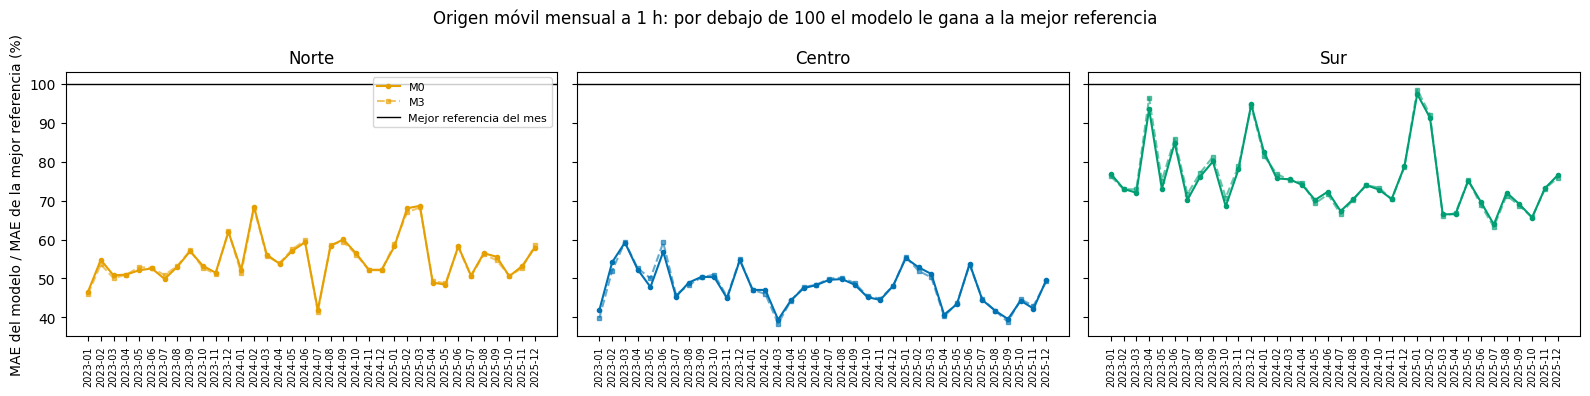

In [15]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for eje, a in zip(ejes, AREAS):
    d = movil[movil["Área"] == NOMBRES[a]]
    for v, estilo in zip(["M0", "M3"], ["-o", "--s"]):
        eje.plot(d["Mes"], 100 * d[v] / d["Mejor referencia"], estilo, ms=3, label=v, color=COLORES[a],
                 alpha=1 if v == "M0" else 0.6)
    eje.axhline(100, color="black", lw=1, label="Mejor referencia del mes")
    eje.set_title(NOMBRES[a])
    eje.tick_params(axis="x", labelrotation=90, labelsize=7)
ejes[0].set_ylabel("MAE del modelo / MAE de la mejor referencia (%)")
ejes[0].legend(fontsize=8)
plt.suptitle("Origen móvil mensual a 1 h: por debajo de 100 el modelo le gana a la mejor referencia")
plt.tight_layout()
plt.show()

## 9. Errores por régimen

Con las predicciones del modelo fijo (A, M0, y B, M3) en la validación de 2025 (spec §8.5):

- **Horas de mayor demanda**, definidas por área y por año (las cuatro horas con más demanda media del periodo que
  se predice), porque el pico se movió del atardecer al mediodía. Además del MAE, la fracción de esas horas en que
  el modelo subestima más que el percentil 90 del error de la mejor referencia (criterio 2 de la spec).
- **Feriados, laborables y fines de semana**, por la fecha del periodo que se predice.
- **Fallas en curso** del COES en t.
- **El Niño**, según la categoría del ICEN **definitivo del mes que se predice**. Es un corte retrospectivo: aquí
  no vale el ICEN con rezago de publicación que ve el modelo (la columna `icen`), porque correría el inicio y el
  fin de cada episodio dos o tres meses.

In [16]:
ICEN_DEFINITIVO = exogenas["icen"].set_index(exogenas["icen"]["mes"].dt.to_period("M"))["icen"]


def por_regimen(nombre_h):
    filas = []
    for a in AREAS:
        t = tramo(datos[nombre_h]["locales"][a], "validacion").reset_index(drop=True)
        adelanto = HORIZONTES[nombre_h] * PASO
        preds = {"M0": predicciones_ablacion[nombre_h]["M0"][a], "M3": predicciones_ablacion[nombre_h]["M3"][a],
                 "Mejor referencia": t[MEJOR_REF[nombre_h][a]].to_numpy()}
        pico = es_hora_pico(t["DateTime"], horas_mayor_demanda(t, adelanto), adelanto)
        objetivo = t["DateTime"] + adelanto
        regimenes = {
            "Horas de mayor demanda": np.where(pico, "Mayor demanda", "Resto"),
            "Día": np.where(t["FeriadoObjetivo"] == 1, "Feriado", np.where(objetivo.dt.day_of_week >= 5, "Fin de semana", "Laborable")),
            "Fallas en curso": np.where(t["fallas_en_curso"] > 0, "Con fallas", "Sin fallas"),
            "El Niño (ICEN del mes)": categoria_icen(objetivo.dt.to_period("M").map(ICEN_DEFINITIVO)).astype(str),
        }
        for corte, etiqueta in regimenes.items():
            tabla = mae_por_grupo(t["real"], preds, etiqueta)
            for grupo, fila in tabla.iterrows():
                filas.append({"Horizonte": nombre_h, "Corte": corte, "Grupo": grupo, "Área": NOMBRES[a],
                              "Periodos": int((etiqueta == grupo).sum()), **fila.to_dict(),
                              "Mejora M0 (%)": 100 * (1 - fila["M0"] / fila["Mejor referencia"]),
                              "Mejora M3 (%)": 100 * (1 - fila["M3"] / fila["Mejor referencia"])})
        for v in ["M0", "M3"]:
            filas.append({"Horizonte": nombre_h, "Corte": "Horas de mayor demanda", "Grupo": f"Subestimación > p90 de la referencia, {v} (%)",
                          "Área": NOMBRES[a], "Periodos": int(pico.sum()),
                          "M0": 100 * subestimacion_sobre_p90(t["real"], preds[v], preds["Mejor referencia"], pico)})
    return pd.DataFrame(filas)


regimenes = pd.concat([por_regimen(h) for h in HORIZONTES], ignore_index=True)
display(regimenes.set_index(["Horizonte", "Corte", "Grupo", "Área"]).round(2))

Periodos     M0     M3  Mejor referencia  Mejora M0 (%)  Mejora M3 (%)
Horizonte Corte                  Grupo                                        Área                                                                         
1h        Horas de mayor demanda Mayor demanda                                Norte      2920  17.96  18.29             39.90          54.98          54.14
                                 Resto                                        Norte     14598  20.01  19.99             38.27          47.72          47.77
          Día                    Feriado                                      Norte       814  22.90  23.14             38.13          39.94          39.32
                                 Fin de semana                                Norte      4752  19.14  19.24             37.44          48.86          48.62
                                 Laborable                                    Norte     11952  19.65  19.66             39.01          49.61          49.60
...                                                                                       ...    ...    ...               ...            ...            ...
24h       Fallas en curso        Sin fallas                                   Sur        1573  58.68  58.66             63.77           7.98           8.02
          El Niño (ICEN del mes) cálida débil                                 Sur        4272  54.65  54.12             66.23          17.48          18.28
                                 neutra                                       Sur       13200  57.39  57.21             65.47          12.35          12.61
          Horas de mayor demanda Subestimación > p90 de la referencia, M0 (%) Sur        2912   2.20    NaN               NaN            NaN            NaN
                                 Subestimación > p90 de la referencia, M3 (%) Sur        2912   2.09    NaN               NaN            NaN            NaN

[66 rows x 6 columns]

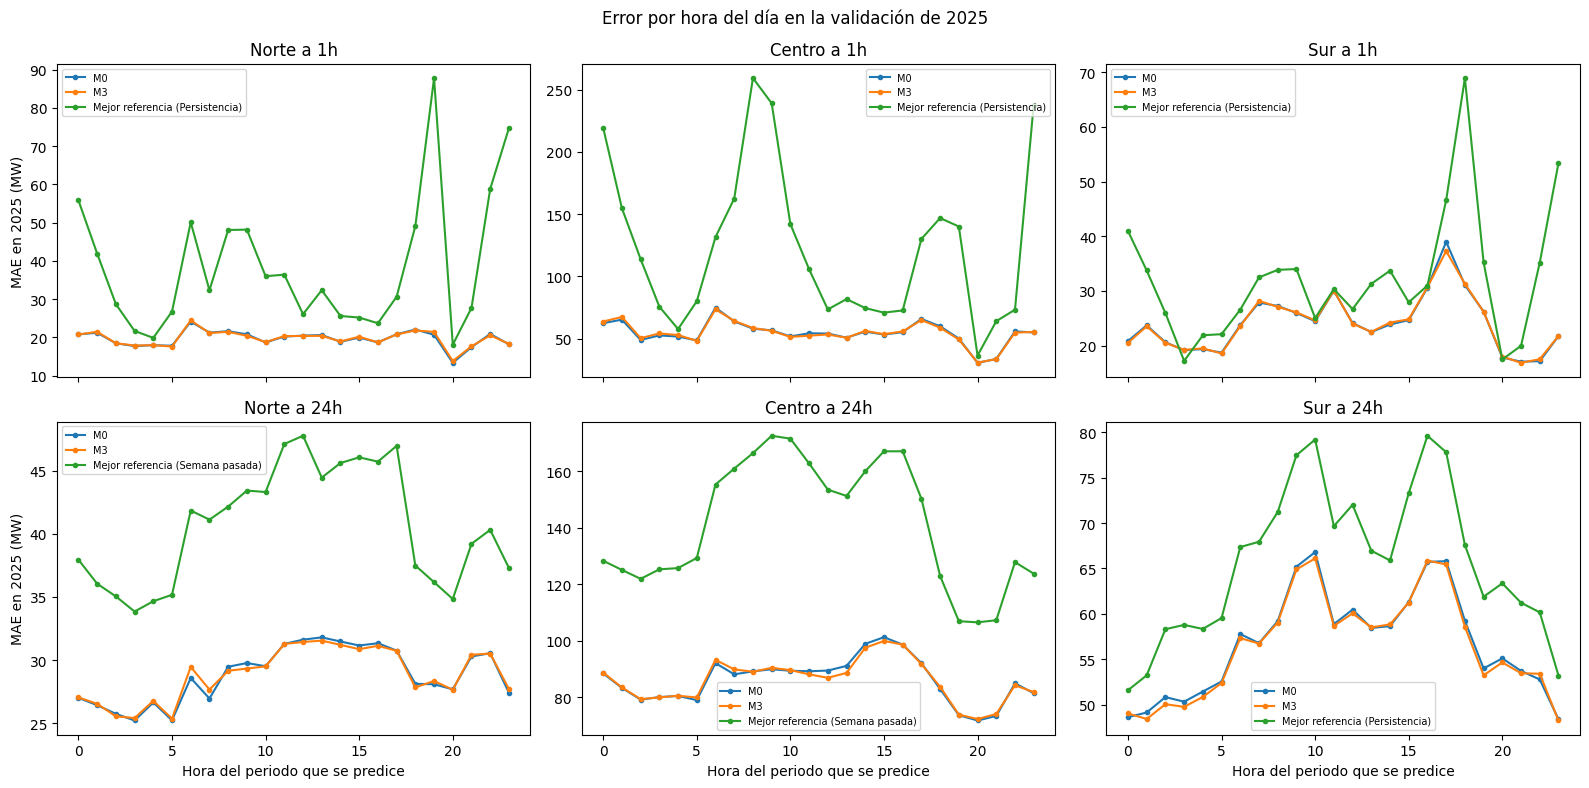

In [17]:
fig, ejes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for i, nombre_h in enumerate(HORIZONTES):
    for eje, a in zip(ejes[i], AREAS):
        t = tramo(datos[nombre_h]["locales"][a], "validacion")
        tabla = mae_por_grupo(t["real"], {"M0": predicciones_ablacion[nombre_h]["M0"][a],
                                          "M3": predicciones_ablacion[nombre_h]["M3"][a],
                                          f"Mejor referencia ({NOMBRES_REF[MEJOR_REF[nombre_h][a]]})": t[MEJOR_REF[nombre_h][a]]},
                              hora_objetivo(t["DateTime"], HORIZONTES[nombre_h] * PASO))
        tabla.plot(ax=eje, marker="o", ms=3)
        eje.set_title(f"{NOMBRES[a]} a {nombre_h}")
        eje.set_xlabel("Hora del periodo que se predice")
        eje.legend(fontsize=7)
    ejes[i][0].set_ylabel("MAE en 2025 (MW)")
plt.suptitle("Error por hora del día en la validación de 2025")
plt.tight_layout()
plt.show()

## 10. Diagnóstico: real contra predicho y residuos

Una semana de 2025 a 1 h y a 24 h, y la dispersión real contra predicho con la distribución de los residuos (el
equivalente de la matriz de confusión en una regresión).

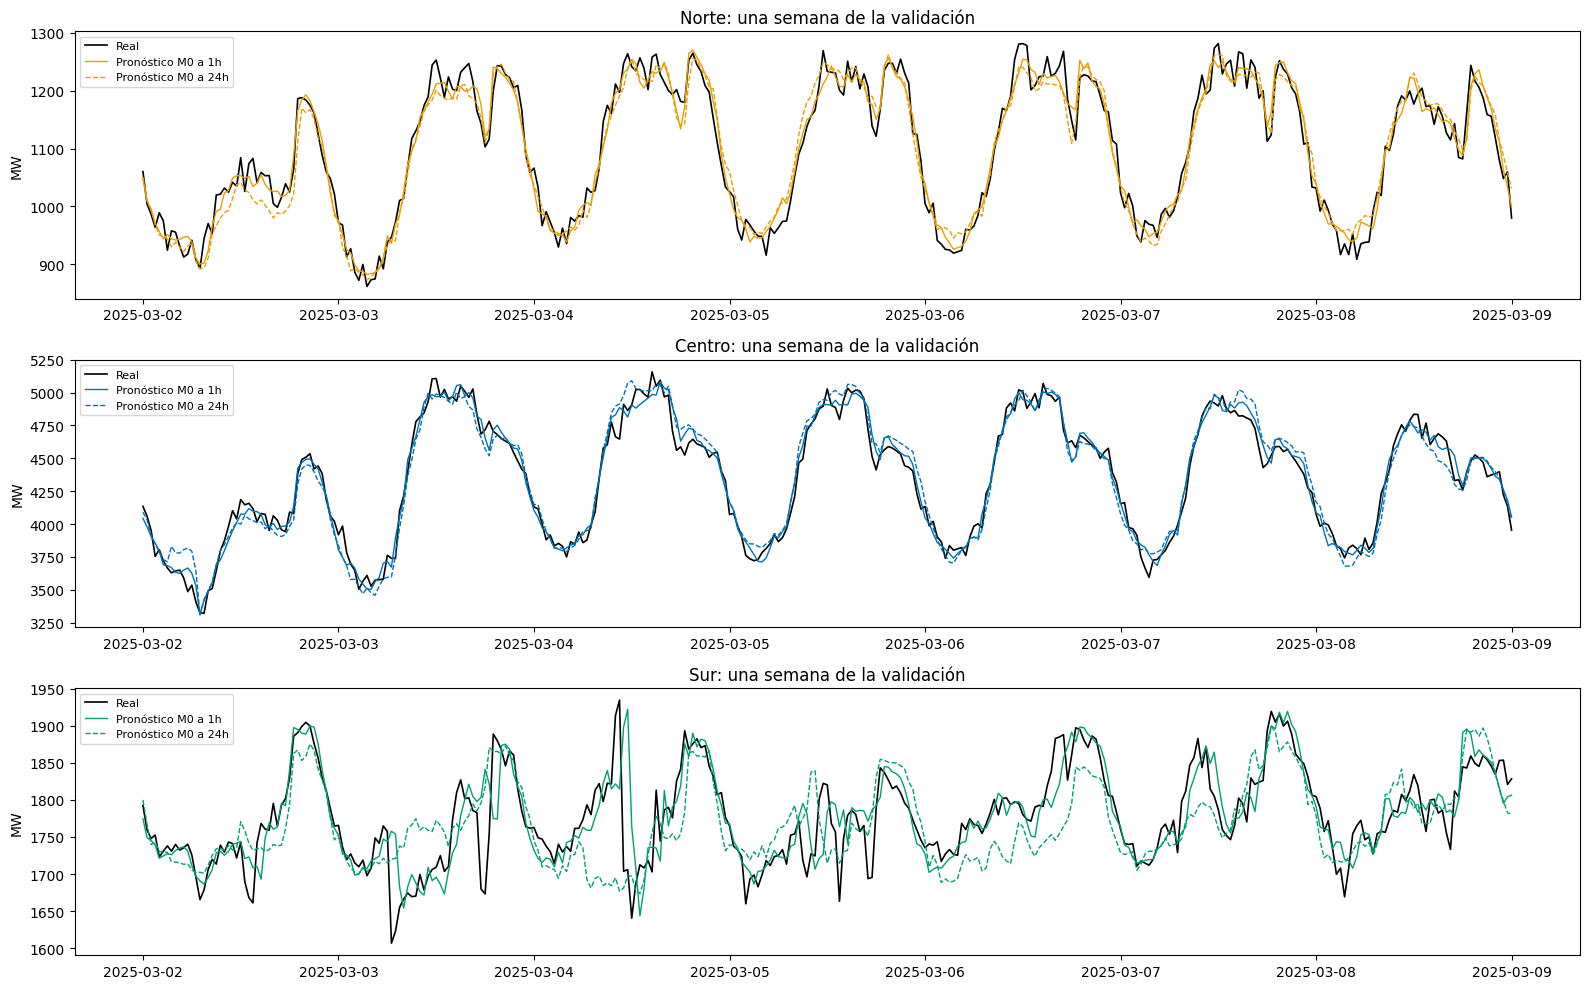

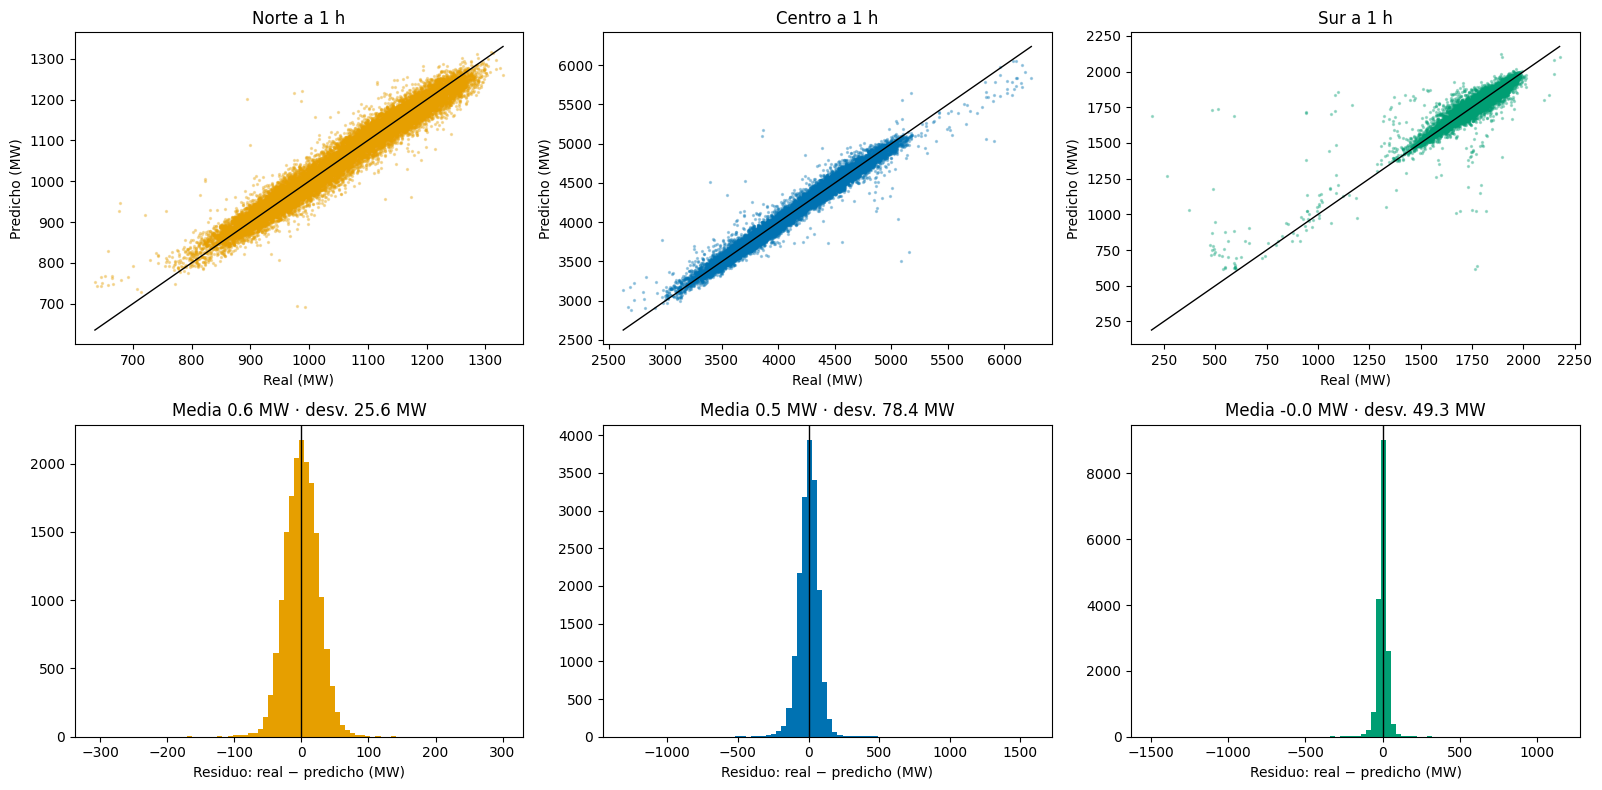

In [18]:
fechas_val_1h = tramo(datos["1h"]["locales"]["CENTRO"], "validacion")["DateTime"]
semana = (fechas_val_1h.min().normalize() + pd.Timedelta(days=60), fechas_val_1h.min().normalize() + pd.Timedelta(days=67))
fig, ejes = plt.subplots(3, 1, figsize=(16, 10))
for eje, a in zip(ejes, AREAS):
    for nombre_h, estilo in zip(HORIZONTES, ["-", "--"]):
        t = tramo(datos[nombre_h]["locales"][a], "validacion").reset_index(drop=True)
        objetivo = t["DateTime"] + HORIZONTES[nombre_h] * PASO
        filtro = objetivo.between(*semana)
        if nombre_h == "1h":
            eje.plot(objetivo[filtro], t["real"][filtro], color="black", lw=1.2, label="Real")
        eje.plot(objetivo[filtro], predicciones_ablacion[nombre_h]["M0"][a][filtro.to_numpy()], estilo, color=COLORES[a], lw=1,
                 label=f"Pronóstico M0 a {nombre_h}")
    eje.set_ylabel("MW")
    eje.set_title(f"{NOMBRES[a]}: una semana de la validación")
    eje.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

fig, ejes = plt.subplots(2, 3, figsize=(16, 8))
for i, a in enumerate(AREAS):
    t = tramo(datos["1h"]["locales"][a], "validacion")
    pred = predicciones_ablacion["1h"]["M0"][a]
    residuo = t["real"].to_numpy() - pred
    ejes[0, i].scatter(t["real"], pred, s=2, alpha=0.3, color=COLORES[a])
    limites = [t["real"].min(), t["real"].max()]
    ejes[0, i].plot(limites, limites, color="black", lw=1)
    ejes[0, i].set(title=f"{NOMBRES[a]} a 1 h", xlabel="Real (MW)", ylabel="Predicho (MW)")
    ejes[1, i].hist(residuo, bins=80, color=COLORES[a])
    ejes[1, i].axvline(0, color="black", lw=1)
    ejes[1, i].set(xlabel="Residuo: real − predicho (MW)", title=f"Media {residuo.mean():.1f} MW · desv. {residuo.std():.1f} MW")
plt.tight_layout()
plt.show()

## 11. Importancia de variables

Por **permutación**, con el modelo elegido y M3 a 1 h, entrenado solo con el entrenamiento y medido en la
validación de 2025: cuánto sube el MAE (en MW) cuando se desordena una variable. Se calcula por área y se agrega por
grupo (demanda y calendario, clima, El Niño, fallas), que es la escala en la que se discute la hipótesis. Se usa
una muestra de la validación para que quepa en el tiempo. `media_24h` no entra: es la escala con que el
modelo vuelve a MW, no una variable, y al desordenarla se rompe esa reconstrucción.

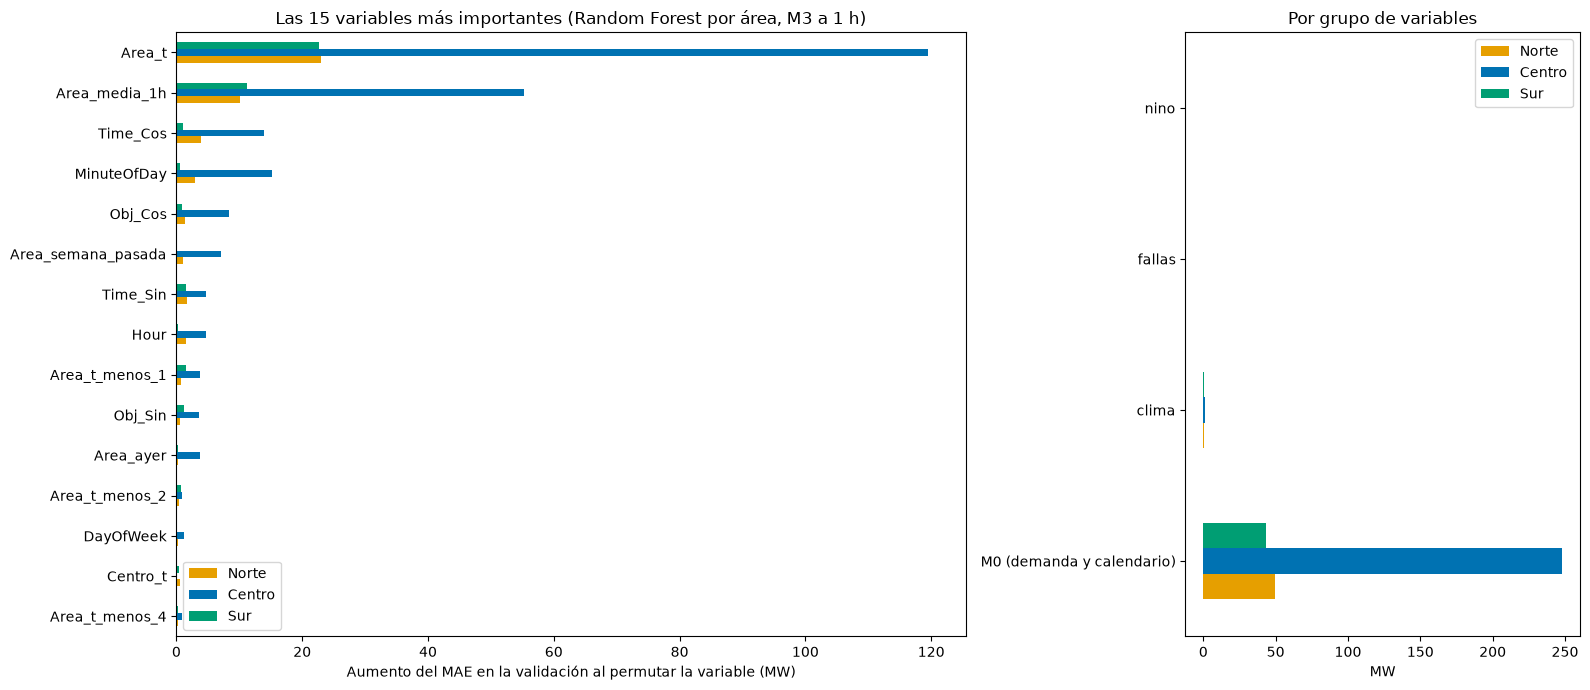

,Norte,Centro,Sur
M0 (demanda y calendario),49.46,247.97,43.37
clima,0.18,1.10,0.23
fallas,0.00,-0.01,0.00
nino,0.02,0.04,0.02


In [19]:
def grupo_de(columna):
    for g, cols in GRUPOS.items():
        if columna in cols:
            return g
    return "M0 (demanda y calendario)"


importancias = {}
for a in AREAS:
    if ELEGIDO.endswith("global"):
        g = datos["1h"]["global"]
        cols = columnas_variante(g, "M3")
        modelo = clone(MODELOS[ELEGIDO]).fit(tramo(g, "entrenamiento")[cols], tramo(g, "entrenamiento")["real"])
        va = tramo(g, "validacion").query("area == @a")
    else:
        d = datos["1h"]["locales"][a]
        cols = columnas_variante(d, "M3")
        modelo = clone(MODELOS[ELEGIDO]).fit(tramo(d, "entrenamiento")[cols], tramo(d, "entrenamiento")["real"])
        va = tramo(d, "validacion")
    muestra = va.sample(min(len(va), 4000 if RAPIDO else 15000), random_state=SEMILLA)
    resultado = permutation_importance(modelo, muestra[cols], muestra["real"], scoring="neg_mean_absolute_error",
                                       n_repeats=3 if RAPIDO else 5, random_state=SEMILLA)
    importancias[NOMBRES[a]] = pd.Series(resultado.importances_mean, index=cols)
importancias = pd.DataFrame(importancias)
importancias = importancias.drop(index="media_24h")  # la escala que lleva la razón a MW: no es una variable
importancias = importancias.loc[importancias.mean(axis=1).sort_values(ascending=False).index]
por_grupo = importancias.groupby(importancias.index.map(grupo_de)).sum()

fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [2, 1]})
importancias.head(15).iloc[::-1].plot.barh(ax=eje1, color=[COLORES[a] for a in AREAS])
eje1.set_xlabel("Aumento del MAE en la validación al permutar la variable (MW)")
eje1.set_title(f"Las 15 variables más importantes ({ELEGIDO}, M3 a 1 h)")
por_grupo.plot.barh(ax=eje2, color=[COLORES[a] for a in AREAS])
eje2.set_title("Por grupo de variables")
eje2.set_xlabel("MW")
plt.tight_layout()
plt.show()
display(por_grupo.round(2))

## 12. Hipótesis para 2026 y modelo final

**Hipótesis para la prueba de 2026.** Se proponen con lo visto en 2025. El grupo las confirma o corrige antes de
correr el notebook 03, y después de mirarla no se editan:

1. **Nivel fuera de lo visto.** El modelo fijo (A, M0) le gana a la mejor referencia a 1 h en las tres áreas, porque
   aprende la razón con la media de 24 h y no el nivel. En el Norte, donde la demanda crece entre 10 y 17 % sobre el
   año anterior, la mejora baja respecto de 2025 (49 %), pero se mantiene por encima de 25 %. A 24 h le gana en el
   Centro y el Norte; el Sur, con 14 % de mejora en 2025, puede perder.
2. **Reentrenar.** Reentrenar cada semana (C − A) ayuda más que en 2025, sobre todo en el Norte, donde en 2025 no se
   distinguía de cero (−0.03 MW): en 2026 la diferencia es negativa y su intervalo no cruza el cero.
3. **Exógenas a 1 h.** M3 − M0 sigue sin distinguirse de cero, como en 2025: la demanda reciente ya absorbe el nivel.
4. **Exógenas a 24 h.** El clima sigue ayudando en el Centro (en 2025, −0.61 MW con M1). Riesgo declarado: la
   temperatura de Lima en octubre de 2026 sale del rango de entrenamiento y los árboles no extrapolan; los días con
   temperatura fuera de ese rango se reportan aparte.
5. **El Niño y fallas.** El ICEN y el Niño 1+2 no mejoran a M0 en ningún horizonte: su efecto llega por el nivel de la
   demanda, que el objetivo en razón ya absorbe. `fallas_en_curso` se mantiene como en 2025 para comparar con la
   validación (aunque en 2025 es mayor que cero en el 91 % de los periodos), y se reporta también M2, que no la lleva.
6. **"Sin efecto" también es un resultado**, y se reporta con su intervalo.

**Modelo final.** El modelo elegido, con M0 y con M3 y a los dos horizontes, entrenado con entrenamiento +
validación (hasta el hueco antes de 2026), se guarda en el Drive (`modelos/sein/`) con sus variables y sus
métricas de 2025, para la app y para el notebook 03. Se guarda **portable** (`portable`): XGBoost pasa a la CPU
para que la app lo cargue en una máquina sin GPU. Las tablas de este notebook quedan en `reportes/sein/modelado/`.
La corrida rápida escribe en carpetas aparte (`*_rapido`), para no pisar lo de una corrida completa.

In [20]:
sufijo = "_rapido" if RAPIDO else ""
carpeta_modelos = RAIZ / "modelos" / f"sein{sufijo}"
carpeta_reportes = RAIZ / "reportes" / "sein" / f"modelado{sufijo}"
carpeta_modelos.mkdir(parents=True, exist_ok=True)
carpeta_reportes.mkdir(parents=True, exist_ok=True)

finales, variables = {}, {}
for nombre_h in HORIZONTES:
    for variante in ["M0", "M3"]:
        clave = f"{nombre_h}_{variante}"
        if ELEGIDO.endswith("global"):
            d = tramo(datos[nombre_h]["global"], "desarrollo")
            variables[clave] = {"global": columnas_variante(d, variante)}
            finales[clave] = {"global": portable(clone(MODELOS[ELEGIDO]).fit(d[variables[clave]["global"]], d["real"]))}
        else:
            finales[clave], variables[clave] = {}, {}
            for a in AREAS:
                d = tramo(datos[nombre_h]["locales"][a], "desarrollo")
                variables[clave][a] = columnas_variante(d, variante)
                finales[clave][a] = portable(clone(MODELOS[ELEGIDO]).fit(d[variables[clave][a]], d["real"]))
joblib.dump(finales, carpeta_modelos / "modelo_final.joblib")
metadatos = {
    "modelo": ELEGIDO,
    "hiperparametros": {k.split("__")[-1]: v for k, v in
                        (busqueda_global if ELEGIDO.endswith("global") else busquedas[ELEGIDO.removesuffix(" por área")]).best_params_.items()},
    "variables": variables,
    "entrenado_hasta": str(tramo(datos["1h"]["global"], "desarrollo")["DateTime"].max()),
    "mejor_referencia_2025": {h: MEJOR_REF[h] for h in HORIZONTES},
    "validacion_2025": json.loads(ablacion[ablacion["Variante"].isin(["M0", "M3"])].to_json(orient="records")),
    "rapido": RAPIDO,
    "dispositivo": DISPOSITIVO,
    "estimador_guardado": {clave: type(next(iter(m.values())).estimador_).__module__ for clave, m in finales.items()},
}
(carpeta_modelos / "modelo_final.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2, default=str))

for nombre_h in HORIZONTES:
    for a in AREAS:
        t = tramo(datos[nombre_h]["locales"][a], "validacion")
        salida = t[["DateTime", "real", *REFERENCIAS]].assign(
            **{f"{p}_{v}": pred[a] for (p, v), pred in predicciones_adaptacion[nombre_h].items()})
        salida.to_csv(carpeta_reportes / f"predicciones_validacion_{nombre_h}_{a.lower()}.csv", index=False)
for nombre, tabla in {"busqueda": tabla_busqueda, "comparacion_validacion_1h": comparacion_val,
                      "comparacion_validacion_24h": comparacion_24h, "ablacion": ablacion, "adaptacion": adaptacion,
                      "efectos_adaptacion": efectos_adaptacion.reset_index(), "origen_movil": movil,
                      "regimenes": regimenes, "importancias": importancias, "importancias_por_grupo": por_grupo}.items():
    tabla.to_csv(carpeta_reportes / f"{nombre}.csv")
print("Modelo en", carpeta_modelos, "· tablas en", carpeta_reportes)

Modelo en /content/datos/modelos/sein · tablas en /content/datos/reportes/sein/modelado


# Conclusiones

Todo lo que sigue es de la validación de 2025 y del origen móvil de 2023 a 2025. La prueba de 2026 no se tocó.

**1. El modelo y por qué.** Por la regla definida antes de la corrida, que elige la mayor mejora media frente a la
mejor referencia de cada área, el elegido es el **Random Forest por área** (43.2 %). Pero los modelos de árboles están
empatados en la práctica: XGBoost por área queda en 42.9 % y el XGBoost global en 42.9 %. XGBoost gana en el Centro
(56.7 frente a 55.5 %) y el Norte, y el Random Forest en el Sur (25.1 frente a 22.9 %), que es lo que decide el
promedio. En la validación cruzada de la búsqueda, XGBoost tuvo menor error (50.3 frente a 51.8 MW). Ridge queda muy
atrás (26.4 %): las interacciones entre la hora, el día y la demanda reciente importan.

**2. Qué tan bueno es.** A 1 h, el error medio en 2025 es de 54.6 MW en el Centro, 19.7 en el Norte y 24.1 en el
Sur (MAPE de 1.3, 1.9 y 1.5 %): entre 55 y 25 % menos que la persistencia, que es la mejor referencia a ese
horizonte. A 24 h la mejora frente a la mejor referencia es de 39 % en el Centro, 29 % en el Norte y 14 % en el
Sur. **El Sur a 24 h es el punto débil** (R² de 0.33).

**3. Estable en el tiempo.** En el origen móvil, el modelo le gana a la mejor referencia del mes en los **108
meses-área** de 2023 a 2025, con una mejora mediana de 44.6 %. Durante El Niño costero de 2023 (marzo a julio), el
Norte se mantuvo entre 47 y 50 %. Los cuatro meses más flojos son del Sur y caen entre diciembre y abril (el peor,
enero de 2025, con 2.6 %).

**4. Donde más importa.** En las cuatro horas de mayor demanda de cada área y año, la mejora se sostiene (55 % en el
Norte, 33 % en el Centro y 35 % en el Sur). El modelo subestima por encima del p90 del error de la mejor referencia
en menos del 1 % de esas horas a 1 h, y entre 1.2 y 2.4 % a 24 h.

**5. Las exógenas casi no aportan (H1 se confirma; H2, solo en parte).** A 1 h ninguna variante se aleja de M0 más
de 0.32 MW (menos del 0.6 % del error), y en la importancia por permutación el clima suma 1.1 MW frente a 248 MW de la
demanda y el calendario en el Centro. A 24 h, el clima mejora el Centro en 0.61 MW (IC 95 %: −1.15 a −0.07), un 0.7 %,
y no se distingue de cero en el Norte ni en el Sur. El Niño y las fallas no ayudan: quitarlos de M3 mejora un poco
el error (El Niño a 1 h en el Centro, −0.40 MW; las fallas a 24 h en el Centro, −0.51 MW). Con el objetivo en razón,
la demanda reciente ya absorbe el nivel que estas variables podrían anticipar.

**6. Reentrenar ayuda poco en un año normal (H3 se confirma).** Reentrenar cada semana baja el error a 1 h como mucho
0.56 MW (Centro, con exógenas), menos del 1 %. Sin exógenas, la mejora se distingue de cero en el Centro (−0.31 MW) y
el Sur (−0.12), pero no en el Norte (−0.03). A 24 h solo se distingue en el Centro con exógenas (−0.59 MW). Reentrenar solo cuando cambia la alerta de ENFEN es peor que cada semana, porque en 2025 la
alerta cambió dos veces. La pregunta de verdad es 2026, cuando el nivel se sale de lo visto.

**7. El modelo global no gana (H4 no se confirma).** Con nueve años por área, apilar las tres no agrega información:
el XGBoost global queda empatado con el XGBoost por área (42.9 % los dos). En Tetuán, con un solo año, el global sí
sumaba entre 5 y 10 %.

**Qué revisar antes de 2026.**

- `fallas_en_curso` es mayor que cero en el 91 % de los periodos de 2025 (15,935 de 17,518): casi siempre hay
  "un evento en curso", así que no separa la operación normal de una falla. Hay que restringir qué cuenta como falla
  (por ejemplo, solo eventos con interrupción de carga) o sacarla de M3.
- La elección del modelo depende del Sur y de una diferencia de 0.3 puntos. Conviene reportar el Random Forest y el
  XGBoost global también en 2026.
- **Sobre la GPU:** XGBoost corre en la GPU y es determinista; el Random Forest se queda en la CPU porque en la GPU
  ninguna implementación era a la vez reproducible y más rápida (ver §3). El modelo final pesa 1 GB y está en el
  Drive (`modelos/sein/`); para la app conviene el XGBoost, que es mucho más liviano.